# Решающие деревья

![](https://drive.google.com/uc?id=13kmqLXa-3FBUJq0Q3XVOkz8TENpVTkqk)

*Source: https://www.upnxtblog.com/index.php/2017/12/06/17-machine-learning-algorithms-that-you-should-know/*

Сами по себе решающие деревья используются в машинном обучении относительно редко, однако очень распространены методы, основанные на их композиции - ансамблях (Random Forest, XGBoost, LightGBM), о которых мы поговорим на дальнейших занятиях.

## Линейные модели или решающие деревья?

Раньше мы разбирали только линейные модели, которые имеют совсем другую природу по отношению к решающим деревьям. Можно ли сказать, что какой-то из этих двух типов моделей всегда лучше? Нет. В зависимости от пространственной структуры данных, один из них будет работать лучше:

- Линейная модель, если данные хорошо линейно разделимы

- Решающие деревья, если данные плохо линейно разделимы (присутствуют только кусочно-линейные или нелинейные зависимости)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [ ]:
plt.rcParams["figure.figsize"] = (11, 6.5)

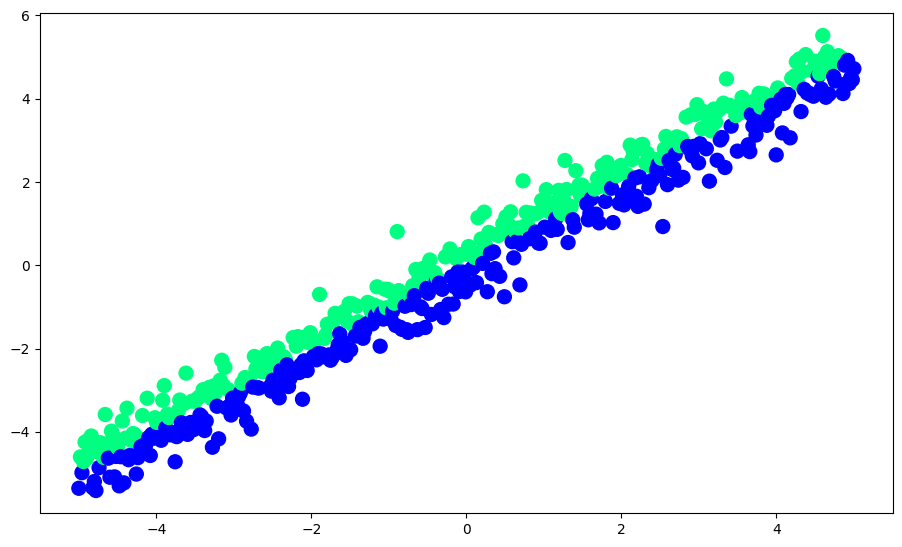

In [ ]:
np.random.seed(13)
n = 500
X = np.zeros(shape=(n, 2))
X[:, 0] = np.linspace(-5, 5, 500)
X[:, 1] = X[:, 0] + 0.5 * np.random.normal(size=n)
y = (X[:, 1] > X[:, 0]).astype(int)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y, cmap="winter")
plt.show();

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)

lr = LogisticRegression(random_state=13)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(f"Linear model accuracy: {accuracy_score(y_pred_lr, y_test):.2f}")

Linear model accuracy: 0.99


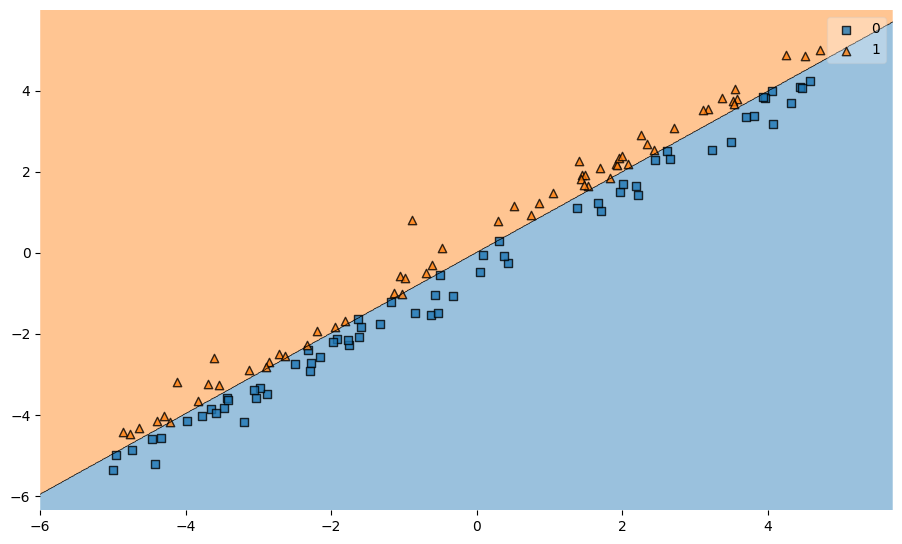

In [ ]:
# !pip install mlxtend
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_test, y_test, lr)

plt.show();

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=13)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print(f"Decision tree accuracy: {accuracy_score(y_pred_dt, y_test):.2f}")

Decision tree accuracy: 0.86


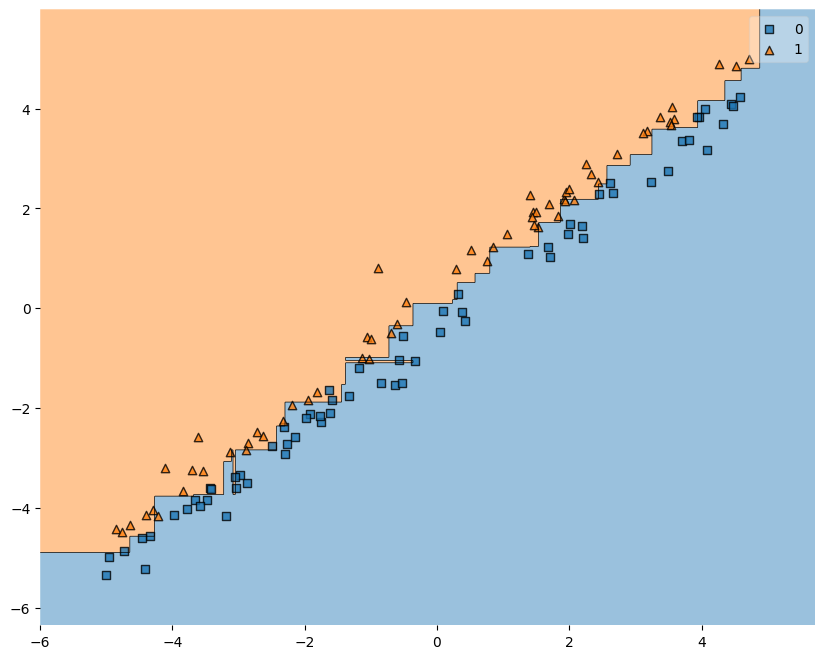

In [ ]:
plt.figure(figsize=(10,8))
plot_decision_regions(X_test, y_test, dt)
plt.show();

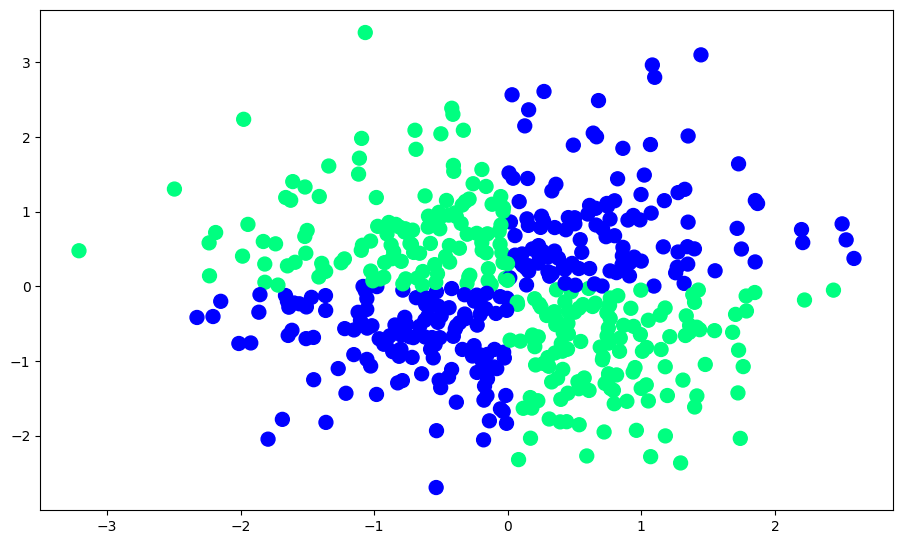

In [ ]:
np.random.seed(13)
X = np.random.randn(500, 2)
y = np.logical_xor(X[:, 0] > 0, X[:, 1] > 0).astype(int)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y, cmap="winter")
plt.show();

Linear model accuracy: 0.39


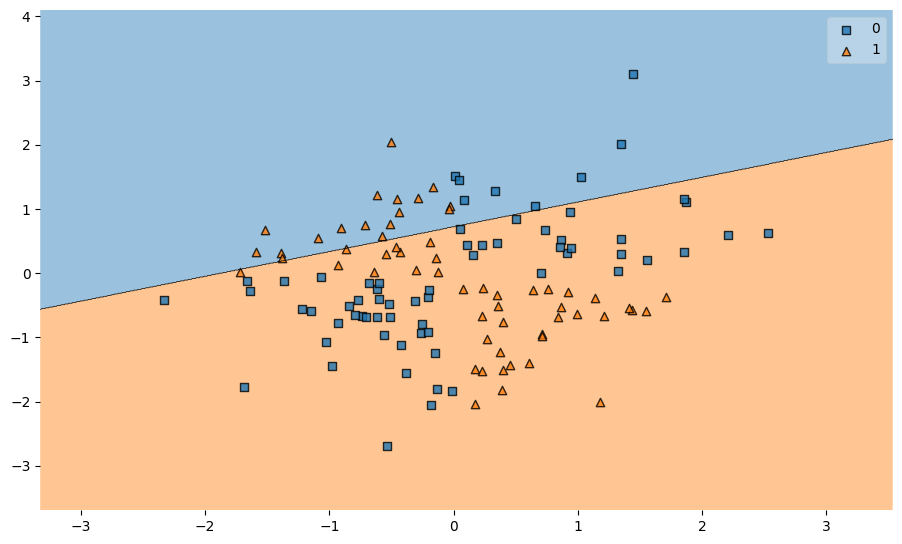

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)

lr = LogisticRegression(random_state=13)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(f"Linear model accuracy: {accuracy_score(y_pred_lr, y_test):.2f}")

plot_decision_regions(X_test, y_test, lr)
plt.show();

Decision tree accuracy: 0.97


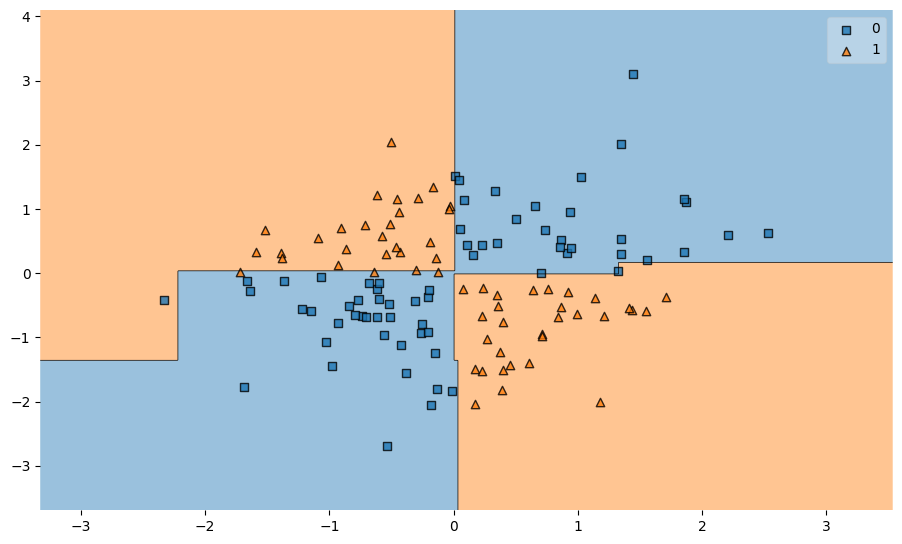

In [ ]:
dt = DecisionTreeClassifier(random_state=13)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print(f"Decision tree accuracy: {accuracy_score(y_pred_dt, y_test):.2f}")

plot_decision_regions(X_test, y_test, dt)
plt.show();

## Переобучение

На лекции рассказывалось, что решающие деревья способны переобучиться под любую выборку, если их никак не регуляризовать: при большом количестве листьев для каждого объекта может выделиться своя область в признаковом пространстве. По сути дерево просто выучивает обучающую выборку, но не выделяет никаких закономерностей среди данных. Давайте убедимся в этом эффекте на практике, сгенерировав два трудноразделимых множества объектов.

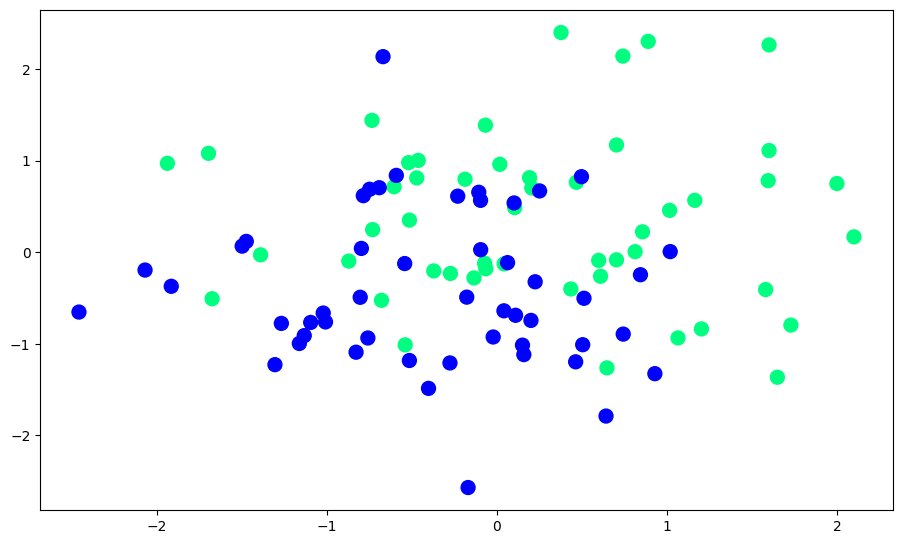

In [ ]:
np.random.seed(13)
n = 100
X = np.random.normal(size=(n, 2))
X[:50, :] += 0.25
X[50:, :] -= 0.25
y = np.array([1] * 50 + [0] * 50)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y, cmap="winter")
plt.show();

Посмотрим, как влияют разные значения гиперпараметров решающего дерева на его структуру:

- `max_depth`: максимальная глубина дерева
- `min_samples_leaf`: минимальное число объектов в вершине дерева, необходимое для того, чтобы она стала листовой

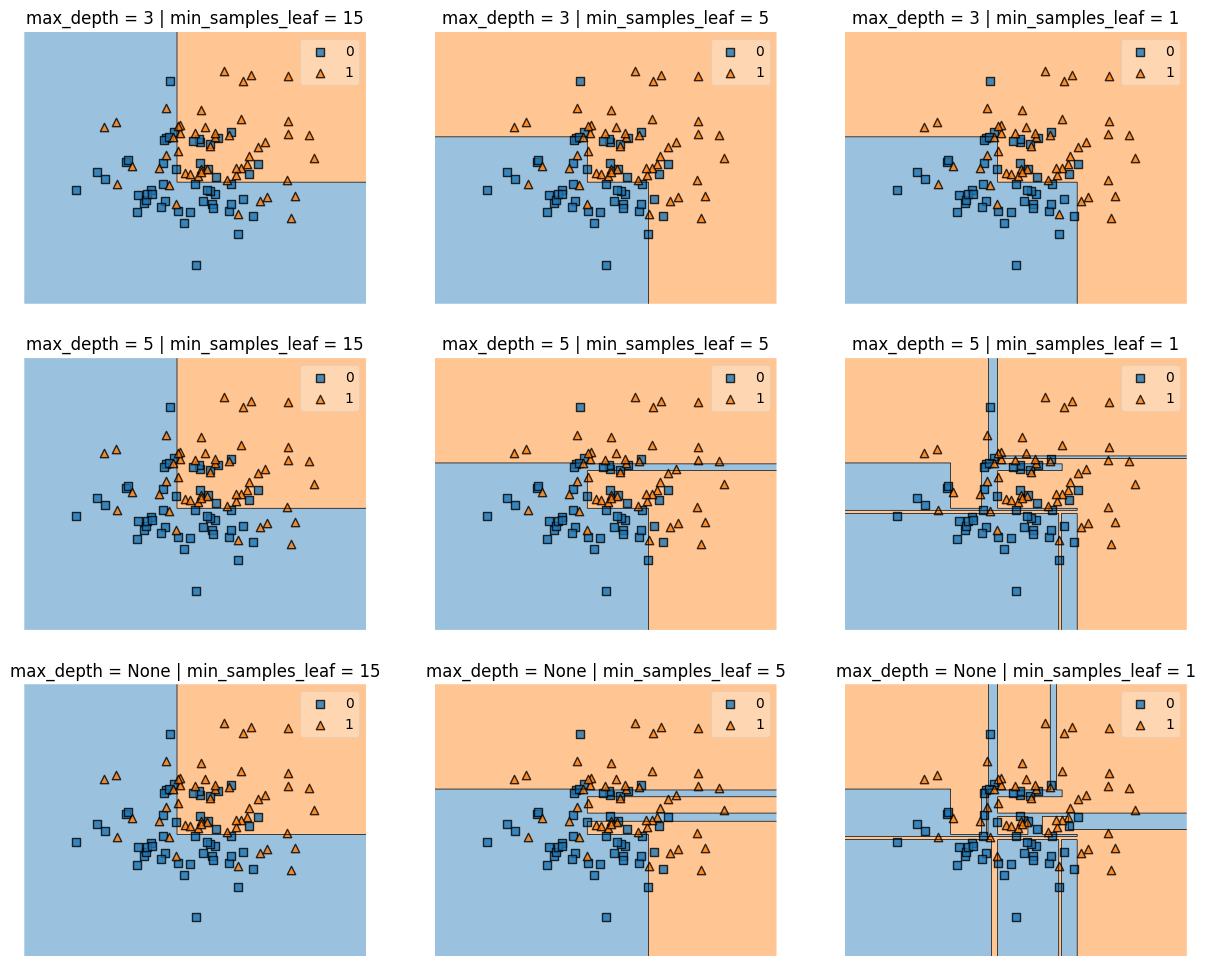

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

for i, max_depth in enumerate([3, 5, None]):
    for j, min_samples_leaf in enumerate([15, 5, 1]):
        dt = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=13)
        dt.fit(X, y)
        ax[i][j].set_title("max_depth = {} | min_samples_leaf = {}".format(max_depth, min_samples_leaf))
        ax[i][j].axis("off")
        plot_decision_regions(X, y, dt, ax=ax[i][j])

plt.show()

На любой выборке (исключая те, где есть объекты с одинаковыми значениями признаков, но разными ответами) можно получить нулевую ошибку - с помощью максимально переобученного дерева:

Decision tree accuracy: 1.00


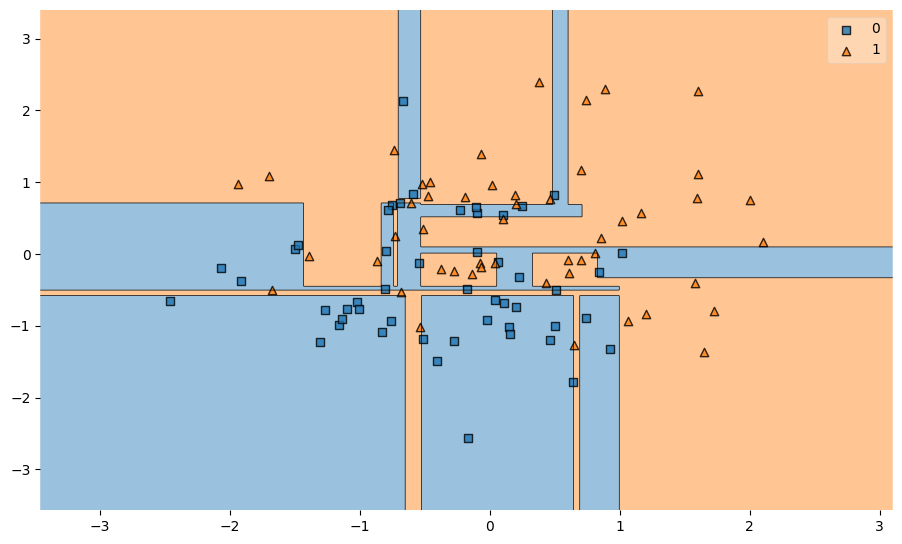

In [ ]:
dt = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, random_state=13)
dt.fit(X, y)

print(f"Decision tree accuracy: {accuracy_score(y, dt.predict(X)):.2f}")

plot_decision_regions(X, y, dt)
plt.show()

Точность 1.00 на обучающей выборке ничего не говорит о качестве на новых данных. Проверим это: сгенерируем много новых объектов из того же распределения и сравним деревья разной сложности.

In [ ]:
import pandas as pd

rng = np.random.default_rng(13)
m = 20000
y_new = rng.integers(0, 2, size=m)
X_new = rng.normal(size=(m, 2)) + np.where(y_new[:, None] == 1, 0.25, -0.25)

rows = []
for max_depth, min_samples_leaf in [(3, 15), (5, 5), (None, 1)]:
    dt = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=13)
    dt.fit(X, y)
    rows.append({
        "max_depth": str(max_depth),
        "min_samples_leaf": min_samples_leaf,
        "accuracy на обучении": accuracy_score(y, dt.predict(X)),
        "accuracy на новых данных": accuracy_score(y_new, dt.predict(X_new)),
    })
pd.DataFrame(rows)

,max_depth,min_samples_leaf,accuracy на обучении,accuracy на новых данных
0,3,15,0.74,0.62025
1,5,5,0.83,0.62095
2,None,1,1.00,0.58785


**Вывод.** Чем сложнее дерево, тем выше точность на обучении (0.74, 0.83, 1.00) и тем ниже на новых данных (0.620, 0.621, 0.588). Полностью выросшее дерево выучило шум обучающей выборки, а не закономерность. Больше примерно 0.64 здесь не получит никакая модель: центры классов сдвинуты всего на 0.25 по каждой оси, классы сильно перекрываются.

## Неустойчивость

Посмотрим, как будет меняться структура дерева, если брать для обучения разные 90%-ые подвыборки исходной выборки.

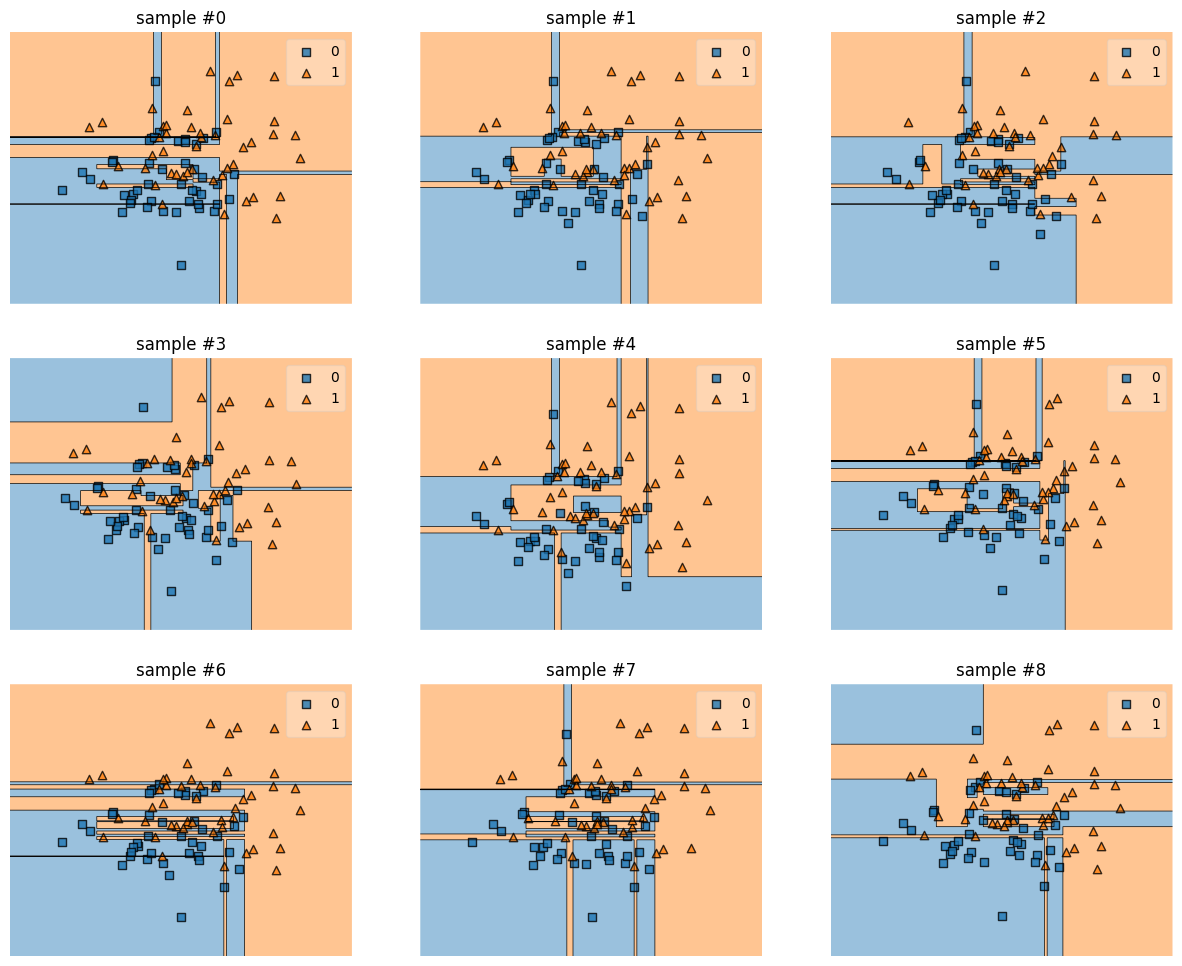

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

for i in range(3):
    for j in range(3):
        seed_idx = 3 * i + j
        np.random.seed(seed_idx)
        dt = DecisionTreeClassifier(random_state=13)
        idx_part = np.random.choice(len(X), replace=False, size=int(0.9 * len(X)))
        X_part, y_part = X[idx_part, :], y[idx_part]
        dt.fit(X_part, y_part)
        ax[i][j].set_title("sample #{}".format(seed_idx))
        ax[i][j].axis("off")
        plot_decision_regions(X_part, y_part, dt, ax=ax[i][j])

plt.show()

## Практика

Данные: расход топлива легковых автомобилей 1970-1982 годов (Auto MPG). Решаем задачу регрессии: предсказываем `mpg`, то есть сколько миль автомобиль проезжает на одном галлоне (чем больше, тем экономичнее).

Признаки:

- `cylinders`: число цилиндров
- `displacement`: объем двигателя (кубические дюймы)
- `horsepower`: мощность (л. с.)
- `weight`: масса (фунты)
- `acceleration`: время разгона до 60 миль/ч (секунды)
- `model_year`: год выпуска (70 означает 1970)

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

auto = pd.read_csv(DATA_URL)
print("Строк в файле:", len(auto))
auto = auto.dropna()   # у 6 автомобилей не указана мощность
print("Строк после удаления пропусков:", len(auto))

feature_names = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
X = auto[feature_names]
y = auto["mpg"].values

print(f"Data shape: {X.shape}")
X.head()

Строк в файле: 398
Строк после удаления пропусков: 392
Data shape: (392, 6)


,cylinders,displacement,horsepower,weight,acceleration,model_year
0,8,307.0,130.0,3504,12.0,70
1,8,350.0,165.0,3693,11.5,70
2,8,318.0,150.0,3436,11.0,70
3,8,304.0,150.0,3433,12.0,70
4,8,302.0,140.0,3449,10.5,70


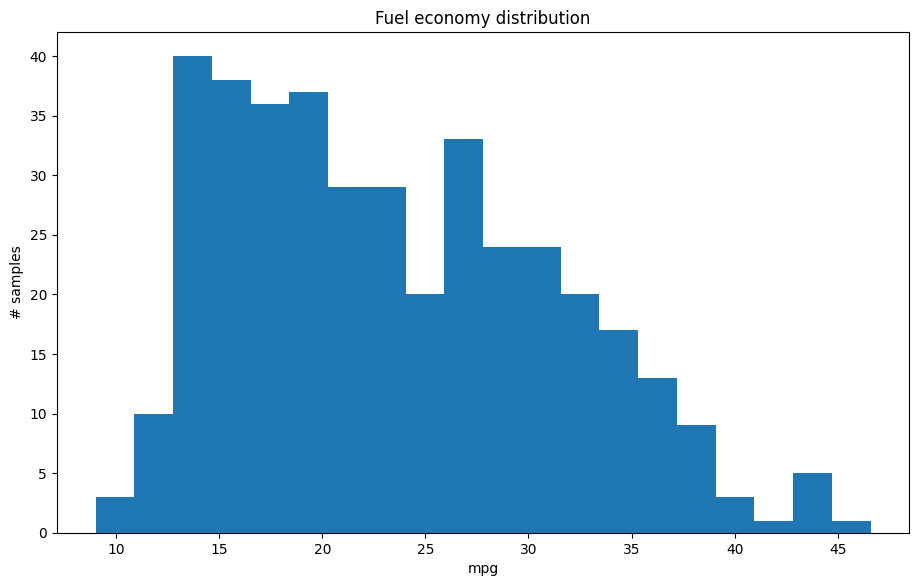

In [ ]:
plt.title("Fuel economy distribution")
plt.xlabel("mpg")
plt.ylabel("# samples")
plt.hist(y, bins=20)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((294, 6), (98, 6), (294,), (98,))

### Решающее дерево: sklearn

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor, plot_tree

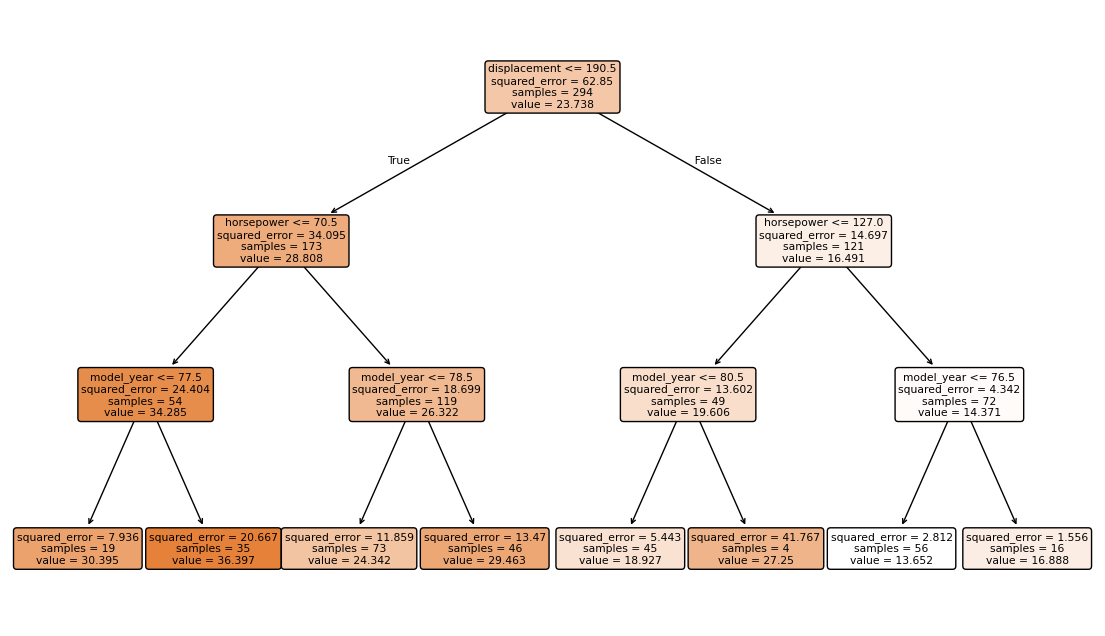

In [ ]:
dt = DecisionTreeRegressor(max_depth=3, random_state=13)
dt.fit(X_train, y_train)

plt.figure(figsize=(14, 8))
plot_tree(dt, feature_names=X.columns, filled=True, rounded=True)
plt.show()

In [ ]:
mean_squared_error(y_test, dt.predict(X_test))

12.859076323757671

**Вывод.** Для сравнения: дисперсия `mpg` на обучающей выборке около 62.9, то есть константный прогноз (среднее) дал бы MSE примерно такого порядка. Дерево глубины 3 снижает ошибку до 12.9 на тесте.

#### Подбор глубины дерева

Глубину нельзя выбирать по ошибке на тестовой выборке: тогда тест перестает быть независимым и оценка качества получается завышенной. Поэтому подбираем глубину по кросс-валидации на обучающей части, а тестовую выборку используем один раз в конце.

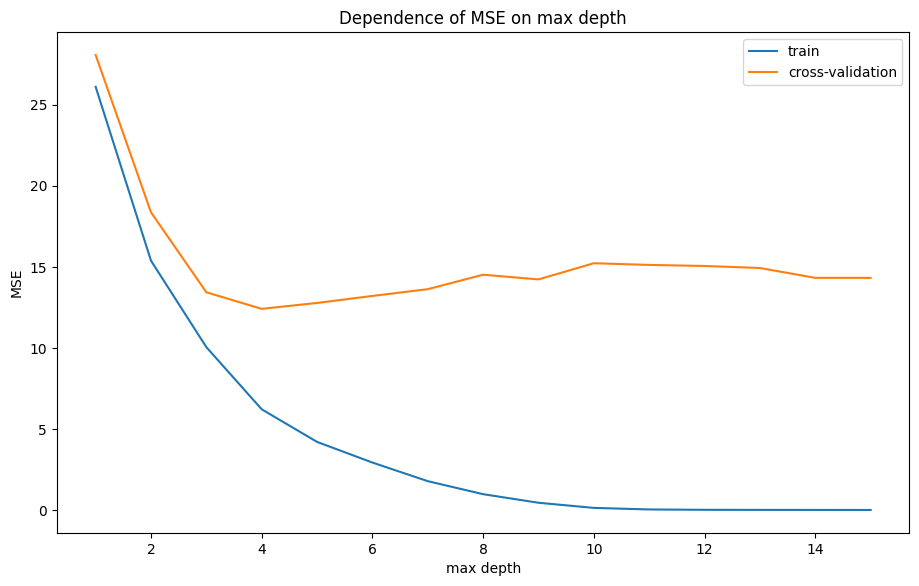

In [ ]:
from sklearn.model_selection import cross_val_score

def cv_mse(model, X_, y_, cv=5):
    return -cross_val_score(model, X_, y_, cv=cv, scoring="neg_mean_squared_error").mean()

max_depth_array = range(1, 16)
train_mse, cv_mse_array = [], []

for max_depth in max_depth_array:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13)
    dt.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, dt.predict(X_train)))
    cv_mse_array.append(cv_mse(dt, X_train, y_train))

plt.plot(max_depth_array, train_mse, label="train")
plt.plot(max_depth_array, cv_mse_array, label="cross-validation")
plt.title("Dependence of MSE on max depth")
plt.xlabel("max depth")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [ ]:
pd.DataFrame({
    "max_depth": max_depth_array,
    "MSE train": train_mse,
    "MSE cv": cv_mse_array,
}).sort_values(by="MSE cv").reset_index(drop=True)

,max_depth,MSE train,MSE cv
0,4,6.211749,12.411140
1,5,4.199246,12.775771
2,6,2.925274,13.208280
3,3,10.046871,13.432221
4,7,1.777403,13.625452
5,9,0.445090,14.227952
6,14,0.002421,14.324230
7,15,0.000000,14.324230
8,8,0.974181,14.517249
9,13,0.005193,14.931416


<details>
<summary><b>Как читать график</b></summary>

Ошибка на обучении падает почти до нуля: глубокое дерево запоминает выборку (на полной глубине около 250 листьев на 294 объекта, то есть практически по объекту в листе). Ошибка по кросс-валидации падает до глубины 4 (12.4), а затем растет до 14.5-15.6: дерево подгоняется под шум. Выбираем глубину 4. Различия между глубинами 4-7 (12.4-13.5) небольшие, так что выбор любой из них был бы разумным.

</details>

In [ ]:
best_depth = max_depth_array[int(np.argmin(cv_mse_array))]

dt = DecisionTreeRegressor(max_depth=best_depth, random_state=13)
dt.fit(X_train, y_train)
print(f"Глубина по кросс-валидации: {best_depth}")
print(f"MSE на тесте (один раз): {mean_squared_error(y_test, dt.predict(X_test)):.2f}")

Глубина по кросс-валидации: 4
MSE на тесте (один раз): 15.86


Для сравнения посмотрим, как выглядела бы кривая на тестовой выборке. Выбирать глубину по ней нельзя, мы смотрим только на ее форму.

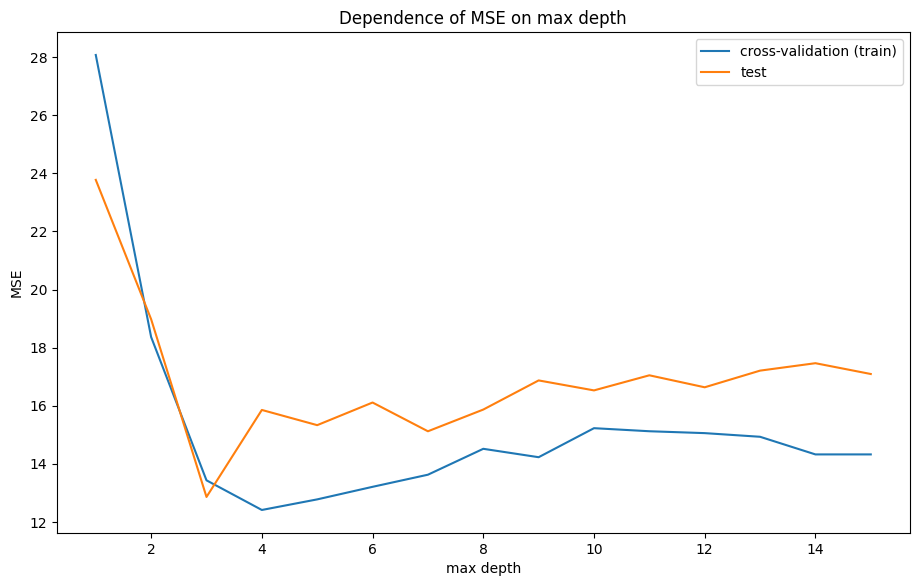

In [ ]:
test_mse = []
for max_depth in max_depth_array:
    dt_ = DecisionTreeRegressor(max_depth=max_depth, random_state=13).fit(X_train, y_train)
    test_mse.append(mean_squared_error(y_test, dt_.predict(X_test)))

plt.plot(max_depth_array, cv_mse_array, label="cross-validation (train)")
plt.plot(max_depth_array, test_mse, label="test")
plt.title("Dependence of MSE on max depth")
plt.xlabel("max depth")
plt.ylabel("MSE")
plt.legend()
plt.show()

**Вывод.** Форма кривых похожа (спад, минимум, рост), но тестовая кривая рваная: в тесте всего 98 объектов. Минимум на тесте приходится на глубину 3 (MSE 12.9), а кросс-валидация выбрала глубину 4 с MSE 15.9 на тесте. Если бы мы выбирали глубину по тесту, то подогнали бы ее под эти 98 объектов, и оценка качества получилась бы слишком оптимистичной. Честная оценка здесь 15.9.

#### Другие ограничения роста дерева

Те же кривые для `min_samples_leaf` и `min_samples_split` при фиксированной глубине. Различие между ними: `min_samples_leaf` запрещает создавать лист меньше заданного размера, а `min_samples_split` запрещает делить узел, в котором объектов меньше заданного числа.

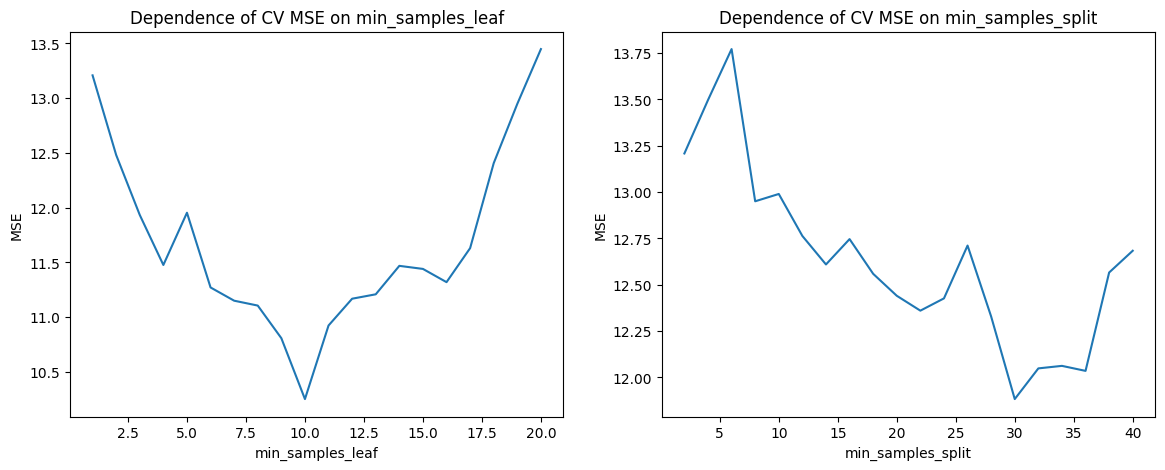

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for a, param, values in [(ax[0], "min_samples_leaf", range(1, 21)), (ax[1], "min_samples_split", range(2, 41, 2))]:
    scores = []
    for v in values:
        model = DecisionTreeRegressor(max_depth=best_depth + 2, random_state=13, **{param: v})
        scores.append(cv_mse(model, X_train, y_train))
    a.plot(list(values), scores)
    a.set_title(f"Dependence of CV MSE on {param}")
    a.set_xlabel(param)
    a.set_ylabel("MSE")

plt.show()

**Вывод.** Ограничения помогают: при `min_samples_leaf=1` кросс-валидация дает 13.2, при `min_samples_leaf=10` около 10.3, а при слишком больших значениях ошибка снова растет (дерево становится слишком простым). Для `min_samples_split` минимум около 30 (11.9). Кривые зубчатые, потому что кросс-валидация на 294 объектах шумная, поэтому различия порядка 0.5 не стоит считать значимыми.

#### Важность признаков

In [ ]:
dt = DecisionTreeRegressor(max_depth=best_depth, random_state=13).fit(X_train, y_train)

pd.DataFrame({
    "feature": X.columns,
    "importance": dt.feature_importances_
}).sort_values(by="importance", ascending=False).reset_index(drop=True)

,feature,importance
0,displacement,0.651724
1,horsepower,0.208927
2,model_year,0.094187
3,weight,0.041569
4,acceleration,0.003593
5,cylinders,0.000000


**Вывод.** Сильнее всего работает `displacement` (0.65), затем `horsepower` (0.21) и `model_year` (0.09). Читать это как "остальные признаки не влияют" нельзя: `displacement`, `weight`, `cylinders` и `horsepower` сильно коррелируют между собой (коэффициент 0.84-0.95), и дерево взяло из них тот, что оказался чуть лучше. Например, у `cylinders` важность 0, хотя в корне он почти так же хорош, как `displacement` (см. ниже). Важность описывает конкретное дерево, а не связь признака с целью.

Влияет ли стандартизация (масштабирование) признаков на результат работы решающего дерева?

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_scaled = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(sc.transform(X_test), columns=X_test.columns, index=X_test.index)

for name, (Xa, Xb) in {"без масштабирования": (X_train, X_test), "со стандартизацией": (X_train_scaled, X_test_scaled)}.items():
    for max_depth in [3, 6]:
        dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13).fit(Xa, y_train)
        print(f"{name}, глубина {max_depth}: MSE на тесте {mean_squared_error(y_test, dt.predict(Xb)):.2f}")

без масштабирования, глубина 3: MSE на тесте 12.86
без масштабирования, глубина 6: MSE на тесте 16.11
со стандартизацией, глубина 3: MSE на тесте 12.86
со стандартизацией, глубина 6: MSE на тесте 16.11


**Вывод.** Результаты совпадают до знака после запятой. Дерево сравнивает значение одного признака с порогом, а стандартизация монотонно преобразует каждый признак отдельно и не меняет порядок объектов. Поэтому разбиения те же, меняются только числовые значения порогов.

## Решающее дерево своими руками

$R$ - множество объектов в разбиваемой вершине, $j$ - номер признака, по которому происходит разбиение, $t$ - порог разбиения. Объекты с $x_j < t$ попадают в левое поддерево $R_\ell$, остальные в правое $R_r$.

Функционал качества, как на лекции (его **максимизируем**):

$$
Q(R, j, t) = H(R) - \frac{|R_\ell|}{|R|}H(R_\ell) - \frac{|R_r|}{|R|}H(R_r) \to \max_{j, t}
$$

$H(R)$ - критерий информативности: мера неоднородности целевой переменной среди объектов множества $R$. Для регрессии с квадратичной ошибкой это дисперсия (с делением на $|R|$).

Так как $H(R)$ для данной вершины от разбиения не зависит, максимизировать $Q$ то же самое, что минимизировать взвешенную сумму $\frac{|R_\ell|}{|R|}H(R_\ell) + \frac{|R_r|}{|R|}H(R_r)$. Иногда именно эту сумму называют критерием ошибки.

Мы реализуем первый шаг построения дерева: выбор признака и порога в корневой вершине. Код максимально понятный, но не оптимальный: в sklearn алгоритм реализован эффективнее.

In [ ]:
train = X_train.copy()
train["target"] = y_train
train.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,target
9,8,390.0,190.0,3850,8.5,70,15.0
98,6,250.0,100.0,3278,18.0,73,16.0
378,4,105.0,63.0,2125,14.7,82,38.0
344,4,86.0,64.0,1875,16.4,81,39.0
30,4,140.0,90.0,2264,15.5,71,28.0


In [ ]:
def H(y_node):
    """Критерий информативности для регрессии: дисперсия (деление на |R|)."""
    return np.var(y_node)


def Q(data, feature, t):
    """Функционал качества разбиения по признаку feature с порогом t."""
    left = data.loc[data[feature] < t, "target"]
    right = data.loc[data[feature] >= t, "target"]
    n = len(data)
    return H(data["target"]) - len(left) / n * H(left) - len(right) / n * H(right)


def best_split(data, feature):
    """Перебирает все возможные пороги по одному признаку."""
    # Порогом может быть любое значение признака, кроме наименьшего:
    # при t = min слева остается пусто. Одинаковые значения не повторяем,
    # потому что разбить объекты с одинаковым значением признака порогом нельзя.
    thresholds = np.sort(data[feature].unique())[1:]
    qs = np.array([Q(data, feature, t) for t in thresholds])
    shares = np.array([(data[feature] < t).mean() for t in thresholds])
    k = qs.argmax()
    return thresholds[k], qs[k], thresholds, qs, shares

Почему перебираем именно уникальные значения: у признака `cylinders` всего несколько разных значений на сотни объектов, и разных разбиений у него столько же, сколько разных значений.

In [ ]:
for f in feature_names:
    print(f"{f:14s} строк: {len(train)}, разных значений: {train[f].nunique()}")

cylinders      строк: 294, разных значений: 5
displacement   строк: 294, разных значений: 74
horsepower     строк: 294, разных значений: 83
weight         строк: 294, разных значений: 266
acceleration   строк: 294, разных значений: 87
model_year     строк: 294, разных значений: 13


Для начала посмотрим на один признак: как меняется $Q$ в зависимости от порога.

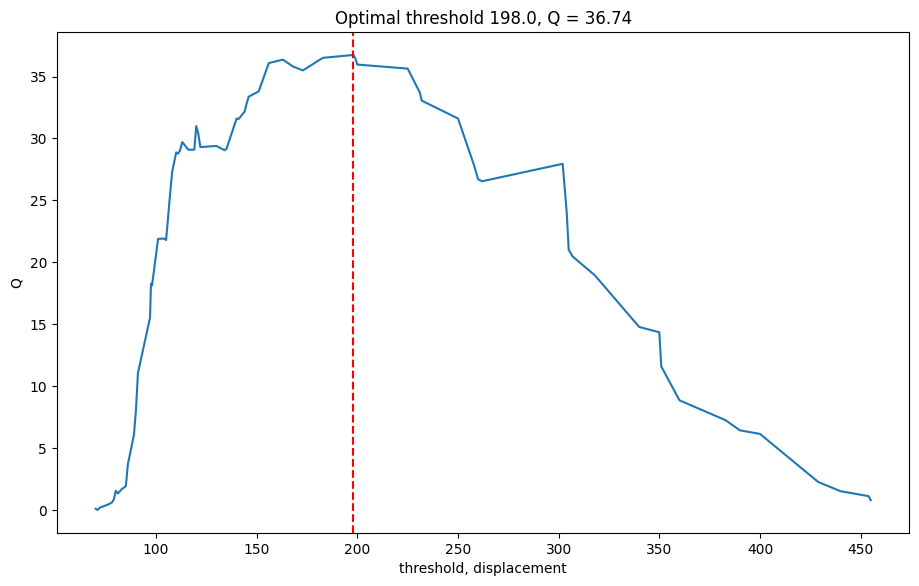

In [ ]:
feature = "displacement"
t_opt, q_opt, thresholds, qs, shares = best_split(train, feature)

plt.plot(thresholds, qs)
plt.axvline(t_opt, color="red", linestyle="--")
plt.xlabel("threshold, " + feature)
plt.ylabel("Q")
plt.title(f"Optimal threshold {t_opt}, Q = {q_opt:.2f}")
plt.show()

Чем больше $Q$, тем лучше, поэтому оптимум достигается в максимуме кривой.

Теперь повторим вычисление для каждого признака. Чтобы удобно сравнивать признаки на одном графике, по оси $x$ отложим долю объектов, попавших в левое поддерево: шкала порогов у признаков разная, а доля всегда от 0 до 1. Величину порога по такому графику определить нельзя, но можно выбрать лучший признак.

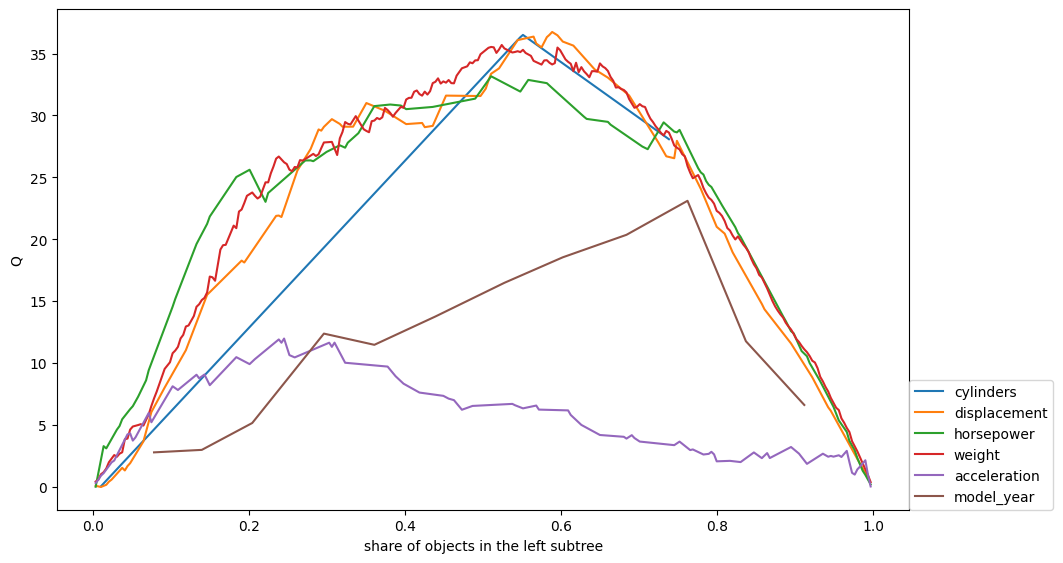

,feature,optimal t,max Q
0,displacement,198.0,36.738284
1,cylinders,6.0,36.500438
2,weight,2807.0,35.688610
3,horsepower,95.0,33.161223
4,model_year,80.0,23.105553
5,acceleration,13.8,11.984028


In [ ]:
results = []
for feat in feature_names:
    t, q, _, qs_, shares_ = best_split(train, feat)
    plt.plot(shares_, qs_, label=feat)
    results.append((feat, t, q))
plt.xlabel("share of objects in the left subtree")
plt.ylabel("Q")
plt.legend(loc=(1, 0))
plt.show()

pd.DataFrame(results, columns=["feature", "optimal t", "max Q"]).sort_values("max Q", ascending=False).reset_index(drop=True)

**Вывод.** Лучший признак `displacement` (Q = 36.7, порог 198), но `cylinders` (36.5) почти не уступает, а `weight` (35.7) отстает ненамного. Признаки сильно коррелируют, и на немного другой выборке в корень мог бы попасть другой признак: это та же неустойчивость, что мы видели выше. Для масштаба: дисперсия `mpg` в корне 62.9, лучшее разбиение убирает из нее 36.7, то есть около 58%.

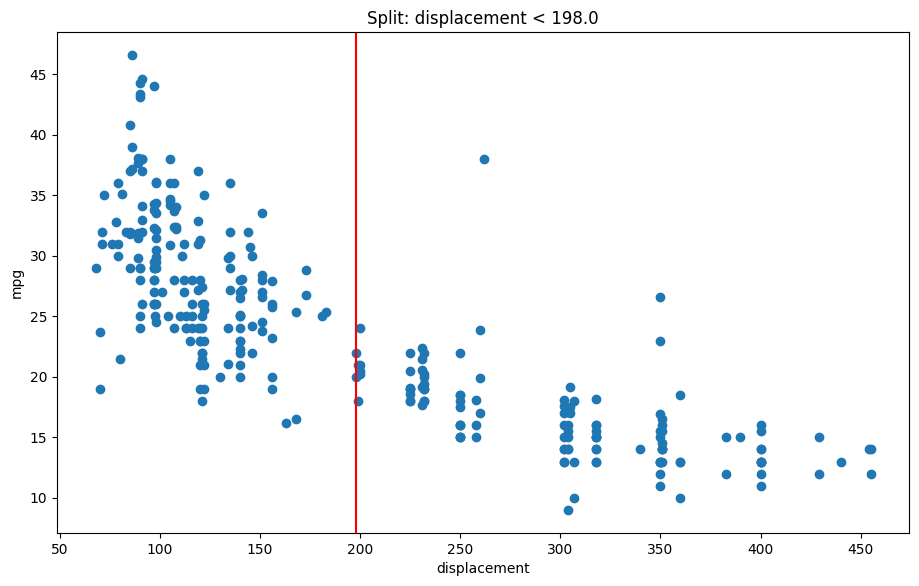

In [ ]:
best_feat, best_t, best_q = max(results, key=lambda r: r[2])

plt.scatter(train[best_feat], train["target"])
plt.axvline(best_t, color="red")
plt.xlabel(best_feat)
plt.ylabel("mpg")
plt.title(f"Split: {best_feat} < {best_t}")
plt.show()

**Вывод.** Слева (малый объем двигателя) `mpg` выше, то есть автомобили экономичнее, и разброс больше; справа `mpg` ниже, и точки лежат компактнее. Прогноз дерева ступенчатый: в каждой части берется среднее. Внутри левой части зависимость от `displacement` еще заметна, ее поймают следующие разбиения.

Сравним с корнем дерева из sklearn, которое строится на тех же данных.

In [ ]:
stump = DecisionTreeRegressor(max_depth=1, random_state=13).fit(X_train, y_train)
sk_feat = X.columns[stump.tree_.feature[0]]
sk_t = stump.tree_.threshold[0]
print(f"sklearn: {sk_feat} <= {sk_t}")
print(f"наша реализация: {best_feat} < {best_t}")

same = ((X_train[sk_feat] <= sk_t) == (X_train[best_feat] < best_t)).all()
print("Разбиение обучающей выборки одинаковое:", same)

sklearn: displacement <= 190.5
наша реализация: displacement < 198.0
Разбиение обучающей выборки одинаковое: True


**Вывод.** Разбиения совпали. Числа порогов отличаются, потому что sklearn берет середину между соседними значениями (190.5), а мы наименьшее значение правой части (198.0). Для объектов обучающей выборки это одно и то же разбиение.

## Критерии информативности для классификации

Для классификации с $K$ классами пусть $p_k$ - доля объектов класса $k$ в вершине. Три критерия:

- ошибка классификации: $H(R) = 1 - \max_k p_k$
- критерий Джини: $H(R) = \sum_k p_k (1 - p_k)$
- энтропия: $H(R) = -\sum_k p_k \log_2 p_k$

Логарифм берем по основанию 2 (так же считает sklearn); для двух классов максимум энтропии равен 1.

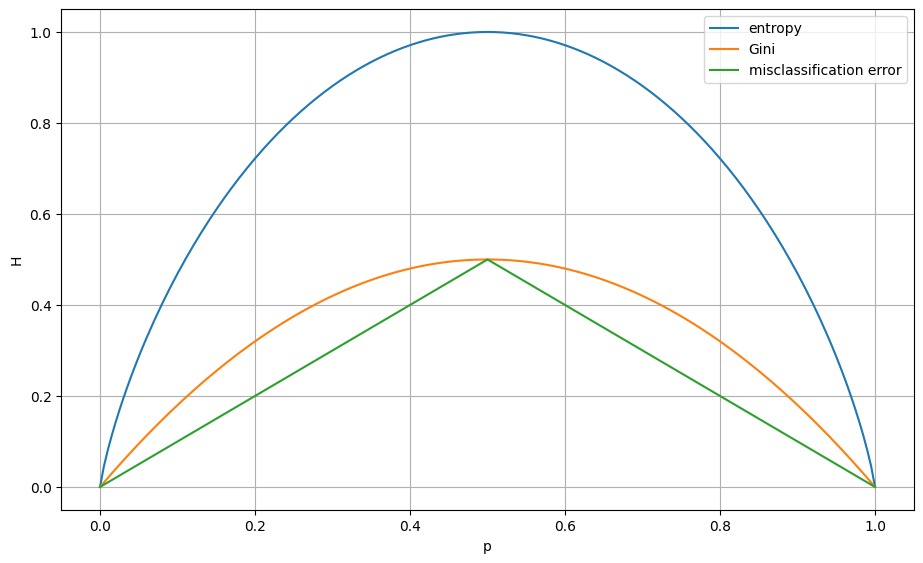

In [ ]:
def error_rate(p):
    return 1 - np.max(p)

def gini(p):
    return np.sum(p * (1 - p))

def entropy(p):
    p = p[p > 0]            # считаем, что 0 * log(0) = 0
    return -np.sum(p * np.log2(p))

def proportions(labels):
    return np.bincount(labels) / len(labels)

pp = np.linspace(0, 1, 201)
curves = {
    "entropy": [entropy(np.array([p, 1 - p])) for p in pp],
    "Gini": [gini(np.array([p, 1 - p])) for p in pp],
    "misclassification error": [error_rate(np.array([p, 1 - p])) for p in pp],
}
for name, values in curves.items():
    plt.plot(pp, values, label=name)
plt.xlabel("p")
plt.ylabel("H")
plt.legend()
plt.grid()
plt.show()

### Пример с лекции: 20 точек на прямой

Синие точки обозначим единицей, оранжевые нулем. Точка с номером $x$ имеет координату $x$ (от 0 до 19).

In [ ]:
points = np.array([0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1])
p0 = proportions(points)
print("Доли классов (оранжевые, синие):", p0)
print(f"Энтропия: {entropy(p0):.3f}")
print(f"Джини: {gini(p0):.3f}")
print(f"Ошибка классификации: {error_rate(p0):.3f}")

Доли классов (оранжевые, синие): [0.55 0.45]
Энтропия: 0.993
Джини: 0.495
Ошибка классификации: 0.450


Прирост информативности для разбиения "левые $t$ точек, остальные справа":

$$Q = H(R) - \frac{|R_\ell|}{|R|}H(R_\ell) - \frac{|R_r|}{|R|}H(R_r)$$

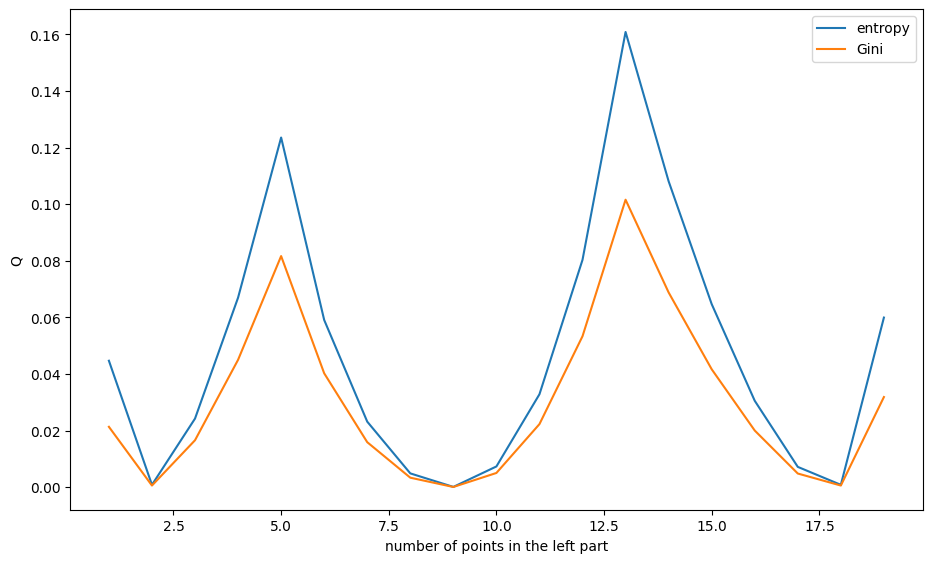

Лучшее разбиение по энтропии: слева 13 точек, т. е. x <= 12
  слева (оранжевые, синие): [5 8], энтропия 0.96
  справа (оранжевые, синие): [6 1], энтропия 0.59
  прирост по энтропии 0.161, по Джини 0.102
Лучшее разбиение по Джини совпадает: True


In [ ]:
def gain_labels(labels, t, H_func):
    left, right = labels[:t], labels[t:]
    n = len(labels)
    return (H_func(proportions(labels))
            - len(left) / n * H_func(proportions(left))
            - len(right) / n * H_func(proportions(right)))

ts = np.arange(1, len(points))
gain_entropy = [gain_labels(points, t, entropy) for t in ts]
gain_gini = [gain_labels(points, t, gini) for t in ts]

plt.plot(ts, gain_entropy, label="entropy")
plt.plot(ts, gain_gini, label="Gini")
plt.xlabel("number of points in the left part")
plt.ylabel("Q")
plt.legend()
plt.show()

t_best = ts[int(np.argmax(gain_entropy))]
left, right = points[:t_best], points[t_best:]
print(f"Лучшее разбиение по энтропии: слева {t_best} точек, т. е. x <= {t_best - 1}")
print(f"  слева (оранжевые, синие): {np.bincount(left, minlength=2)}, энтропия {entropy(proportions(left)):.2f}")
print(f"  справа (оранжевые, синие): {np.bincount(right, minlength=2)}, энтропия {entropy(proportions(right)):.2f}")
print(f"  прирост по энтропии {max(gain_entropy):.3f}, по Джини {gain_gini[int(np.argmax(gain_entropy))]:.3f}")
print("Лучшее разбиение по Джини совпадает:", ts[int(np.argmax(gain_gini))] == t_best)

**Вывод.** Исходная энтропия 0.993. Лучшее разбиение проходит между x = 12 и x = 13: слева 13 точек (5 оранжевых и 8 синих, энтропия 0.96), справа 7 точек (6 и 1, энтропия 0.59), прирост 0.161. Джини выбирает то же самое. Ни одна из частей не стала чистой, поэтому дерево будет делить дальше.

### Чем ошибка классификации хуже Джини и энтропии

В корне 400 объектов класса 0 и 400 объектов класса 1. Сравним два разбиения: A делит на (300 и 100) и (100 и 300), B на (400 и 200) и (0 и 200).

In [ ]:
def weighted(parts, H_func):
    n = sum(sum(part) for part in parts)
    return sum(sum(part) / n * H_func(np.array(part) / sum(part)) for part in parts)

splits = {"A: (300,100) и (100,300)": [(300, 100), (100, 300)],
          "B: (400,200) и (0,200)": [(400, 200), (0, 200)]}

pd.DataFrame({
    name: {"ошибка": weighted(parts, error_rate), "Джини": weighted(parts, gini), "энтропия": weighted(parts, entropy)}
    for name, parts in splits.items()
}).T

,ошибка,Джини,энтропия
"A: (300,100) и (100,300)",0.25,0.375000,0.811278
"B: (400,200) и (0,200)",0.25,0.333333,0.688722


**Вывод.** Ошибка классификации у обоих разбиений одинаковая (0.25), хотя B лучше: оно выделяет полностью чистый лист (0 и 200), а остаток легче делить дальше. Джини (0.333 против 0.375) и энтропия (0.69 против 0.81) это различают. Ошибка классификации учитывает только долю самого частого класса и меняется линейно, поэтому разбиения, равные по ней, не различает.

### Классификация на ирисах

Глубина: 5 | листьев: 9


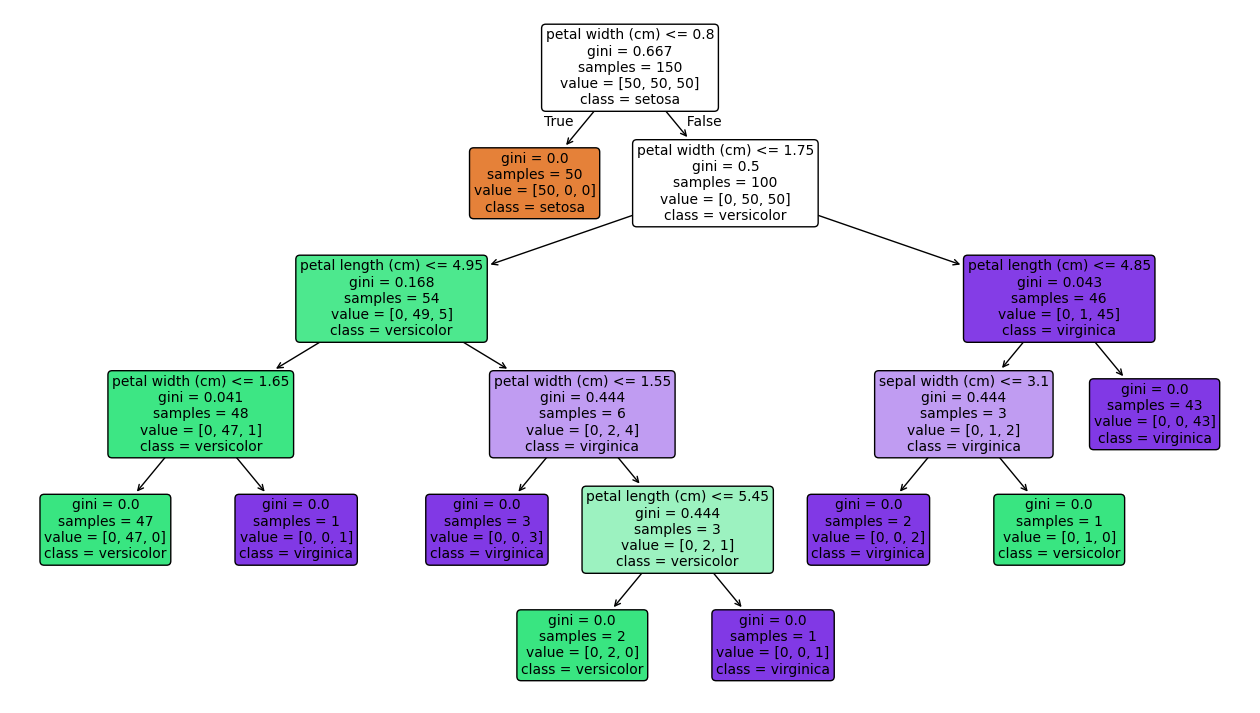

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold

iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target

tree_iris = DecisionTreeClassifier(random_state=0).fit(X_iris, y_iris)
print("Глубина:", tree_iris.get_depth(), "| листьев:", tree_iris.get_n_leaves())

plt.figure(figsize=(16, 9))
plot_tree(tree_iris, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True)
plt.show()

**Вывод.** 9 листьев, глубина 5, в корне ширина лепестка ≤ 0.8 отделяет все 50 объектов setosa (gini = 0). Все листья чистые, среди них есть листья из одного-двух объектов: признак переобучения. Верхние уровни дерева воспроизводятся всегда, а в нижних бывают разбиения с одинаковым качеством, и тогда результат зависит от `random_state` (попробуйте 0, 1, 2).

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(criterion=criterion, max_depth=3, random_state=0)
    scores = cross_val_score(model, X_iris, y_iris, cv=skf)
    print(f"{criterion:8s} accuracy по кросс-валидации: {scores.mean():.3f} ± {scores.std():.3f}")

gini     accuracy по кросс-валидации: 0.953 ± 0.034
entropy  accuracy по кросс-валидации: 0.953 ± 0.034


**Вывод.** Качество одинаковое (0.953 ± 0.034). На практике выбор между Джини и энтропией почти не влияет на результат. Джини чуть быстрее считается (нет логарифма), поэтому он используется в sklearn по умолчанию.

## Стрижка дерева (прунинг)

Строим дерево без ограничений, затем "стрижем" его, минимизируя

$$R_\alpha(T) = R(T) + \alpha |T|,$$

где $R(T)$ - суммарная информативность листьев (на обучающей выборке), $|T|$ - число листьев, $\alpha \ge 0$ - штраф за сложность. При $\alpha = 0$ получаем полное дерево, с ростом $\alpha$ дерево становится все меньше. В sklearn параметр называется `ccp_alpha`, а все "критические" значения $\alpha$ для данного дерева возвращает `cost_complexity_pruning_path`.

Число различных значений alpha: 217


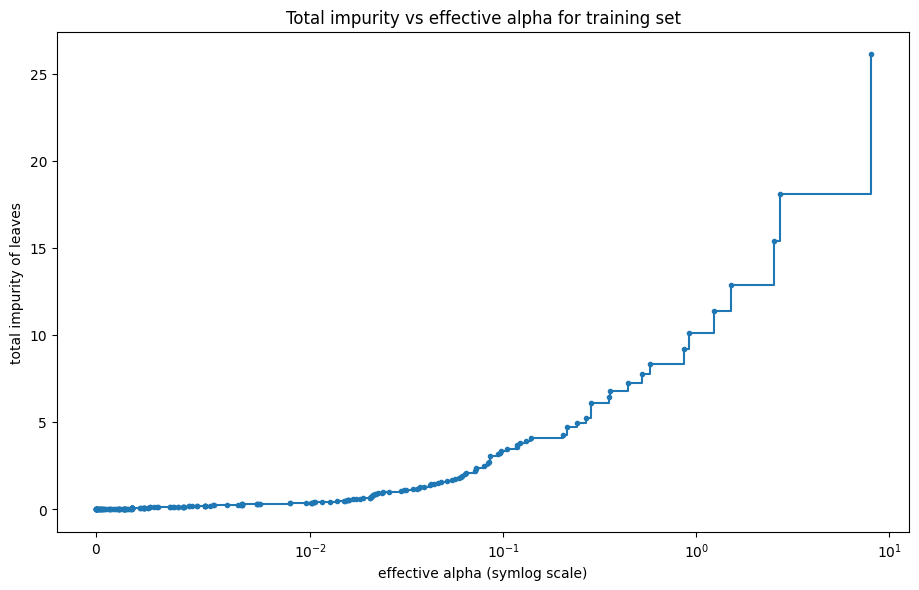

In [ ]:
full = DecisionTreeRegressor(random_state=13).fit(X_train, y_train)
path = full.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas[:-1], path.impurities[:-1]   # последнее значение - дерево из одного корня
print("Число различных значений alpha:", len(ccp_alphas))

plt.plot(ccp_alphas, impurities, marker="o", drawstyle="steps-post", markersize=3)
plt.xscale("symlog", linthresh=0.01)
plt.xlabel("effective alpha (symlog scale)")
plt.ylabel("total impurity of leaves")
plt.title("Total impurity vs effective alpha for training set")
plt.show()

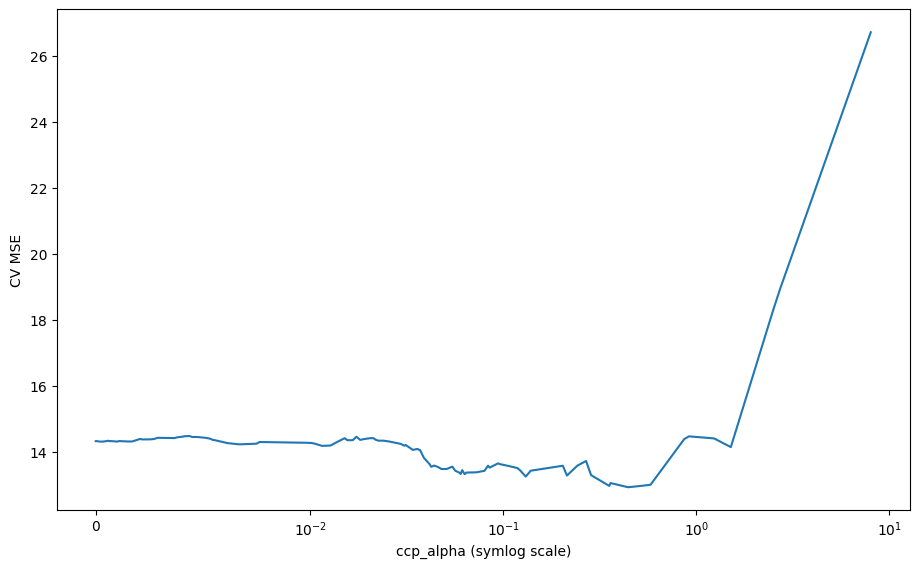

Лучший alpha по кросс-валидации: 0.4432


In [ ]:
cv_alpha = [cv_mse(DecisionTreeRegressor(ccp_alpha=a, random_state=13), X_train, y_train) for a in ccp_alphas]

plt.plot(ccp_alphas, cv_alpha)
plt.xscale("symlog", linthresh=0.01)
plt.xlabel("ccp_alpha (symlog scale)")
plt.ylabel("CV MSE")
plt.show()

best_alpha = ccp_alphas[int(np.argmin(cv_alpha))]
print(f"Лучший alpha по кросс-валидации: {best_alpha:.4f}")

In [ ]:
models = {
    "полное дерево": DecisionTreeRegressor(random_state=13),
    f"max_depth={best_depth} (по CV)": DecisionTreeRegressor(max_depth=best_depth, random_state=13),
    f"прунинг, ccp_alpha={best_alpha:.3f} (по CV)": DecisionTreeRegressor(ccp_alpha=best_alpha, random_state=13),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        "модель": name,
        "листьев": model.get_n_leaves(),
        "глубина": model.get_depth(),
        "MSE cv": cv_mse(model, X_train, y_train),
        "MSE test": mean_squared_error(y_test, model.predict(X_test)),
    })
pd.DataFrame(rows).set_index("модель")

,листьев,глубина,MSE cv,MSE test
модель,,,,
полное дерево,246,15,14.32423,17.092755
max_depth=4 (по CV),16,4,12.41114,15.855262
"прунинг, ccp_alpha=0.443 (по CV)",11,4,12.92550,16.681243


**Вывод.** Оба способа заметно лучше полного дерева (246 листьев, MSE на кросс-валидации 14.5). Ограничение глубины и прунинг между собой различаются в пределах шума: на этих данных прунинг не дал выигрыша по сравнению с простым `max_depth`, зато потребовал дополнительного подбора. Это одна из причин, почему на практике деревья чаще регуляризуют ограничением глубины или размера листа, а в ансамблях прунинг обычно не нужен.

## Бонус: дерево глубины 2 своими руками

Используя функции `H`, `Q` и `best_split` из раздела выше, реализуйте рекурсивное построение дерева и сравните его с деревом из sklearn.

1. Напишите функцию `build_tree(data, depth)`. Если `depth == 0` или в узле меньше двух объектов с разными ответами, верните лист: `{"leaf": среднее значение target}`. Иначе найдите лучшую пару (признак, порог) среди всех признаков, разделите данные и рекурсивно постройте левое и правое поддеревья.
2. Напишите функцию `predict_one(tree, row)`, идущую от корня к листу.
3. Постройте дерево глубины 2 на `train`, посчитайте MSE на тесте и сравните признаки и пороги с `DecisionTreeRegressor(max_depth=2)`.

In [ ]:
# Ваш код

displacement < 198.0
    horsepower < 71.0
        leaf: 34.29
    else
        leaf: 26.32
else
    horsepower < 129.0
        leaf: 19.61
    else
        leaf: 14.37

MSE на тесте (наше дерево): 18.98
MSE на тесте (sklearn):     18.98

|--- displacement <= 190.50
|   |--- horsepower <= 70.50
|   |   |--- value: [34.29]
|   |--- horsepower >  70.50
|   |   |--- value: [26.32]
|--- displacement >  190.50
|   |--- horsepower <= 127.00
|   |   |--- value: [19.61]
|   |--- horsepower >  127.00
|   |   |--- value: [14.37]

